# Computer Vision

Let's do some very basic computer vision. We're going to import the MNIST handwritten digits data and $k$NN to predict values (i.e. "see/read").

1. To load the data, run the following code in a chunk:
```
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
```
The `y_test` and `y_train` vectors, for each index `i`, tell you want number is written in the corresponding index in `X_train[i]` and `X_test[i]`. The value of `X_train[i]` and `X_test[i]`, however, is a 28$\times$28 array whose entries contain values between 0 and 256. Each element of the matrix is essentially a "pixel" and the matrix encodes a representation of a number. To visualize this, run the following code to see the first ten numbers:
```
import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5): 
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()
```
OK, those are the data: Labels attached to handwritten digits encoded as a matrix.

2. What is the shape of `X_train` and `X_test`? What is the shape of `X_train[i]` and `X_test[i]` for each index `i`? What is the shape of `y_train` and `y_test`?
3. Use Numpy's `.reshape()` method to covert the training and testing data from a matrix into an vector of features. So, `X_test[index].reshape((1,784))` will convert the $index$-th element of `X_test` into a $28\times 28=784$-length row vector of values, rather than a matrix. Turn `X_train` into an $N \times 784$ matrix $X$ that is suitable for scikit-learn's kNN classifier where $N$ is the number of observations and $784=28*28$ (you could use, for example, a `for` loop).
4. Use the reshaped `X_test` and `y_test` data to create a $k$-nearest neighbor classifier of digit. What is the optimal number of neighbors $k$? If you can't determine this, play around with different values of $k$ for your classifier.
5. For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy, compute a confusion matrix, and explain your findings.
6. For your confusion matrix, which mistakes are most likely? Do you find any interesting patterns?
7. So, this is how computers "see." They convert an image into a matrix of values, that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data. To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data. (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Marilyn, Maya, Jiei

**Date:**11/3

In [8]:
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

7 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  84 185 159 151  60  36   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0 222 254 254 254 254 241 198 198 198 198 198 198 19

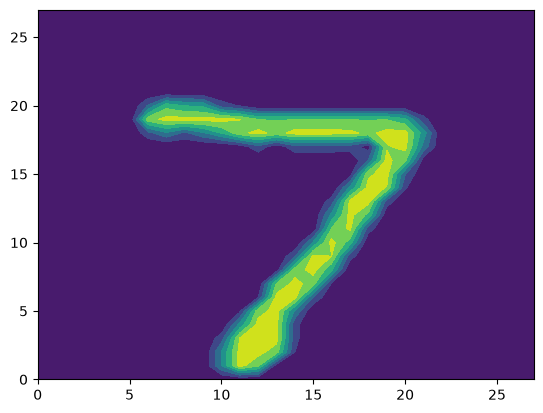

2 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 116 125 171 255 255 150  93   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0 169 253 253 253 253 253 253 218  30   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0 169 253 253 253 213 142 176 253 253 122   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  52 250 253 210  32  12   0   6 206 253 140   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  77 251 210  25   0   0   0 122 248 253  65   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  31  18   0   0   0   0 209 253 253  65   

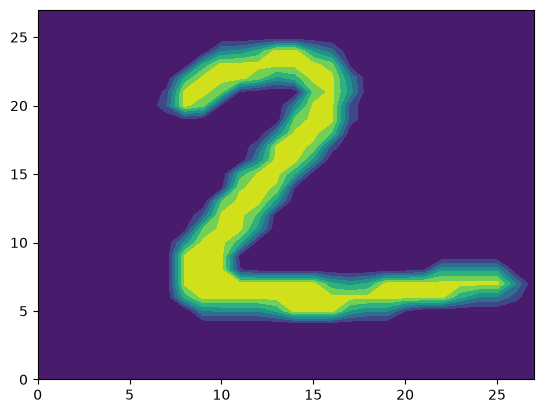

1 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  38 254 109   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  87 252  82   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 135 241   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  45 244 150   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  84 254  63   

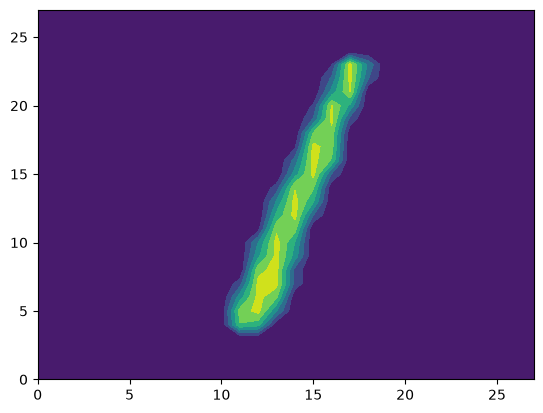

0 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  11 150 253 202  31   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  37 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  21 197 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 110 190 251 251 251 253 169 109  62   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 253 251 251 251 251 253 251 251 22

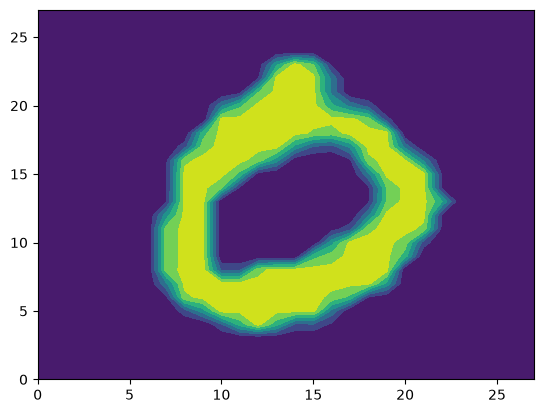

4 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  50 224   0   0   0   0   0   0   0  70  29   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 121 231   0   0   0   0   0   0   0 148 168   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   4 195 231   0   0   0   0   0   0   0  96 210  11   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  69 252 134   0   0   0   0   0   0   

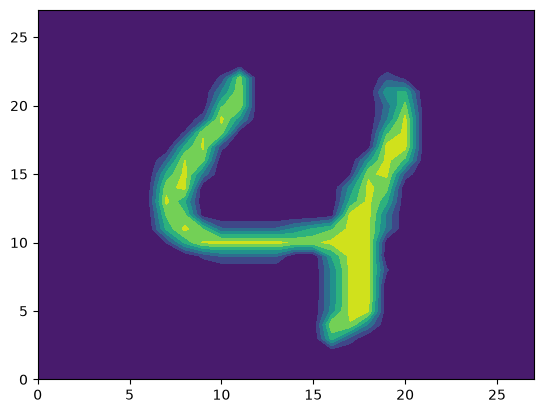

In [9]:


import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5): 
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()

In [10]:
print("q2")
print(X_train.shape)
print(X_test.shape)
print(X_train[0].shape)
print(X_test[0].shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

q2
(60000, 28, 28)
(10000, 28, 28)
(28, 28)
(28, 28)
(10000, 28, 28)
(60000,)
(10000,)


In [11]:
print("q3")
X = np.zeros((X_train.shape[0], 784))
for i in range(X_train.shape[0]):
    X[i] = X_train[i].reshape((1, 784))

Xt = np.zeros((X_test.shape[0], 784))
for i in range(X_test.shape[0]):
    Xt[i] = X_test[i].reshape((1, 784))

print(X.shape, Xt.shape)

q3
(60000, 784) (10000, 784)


In [12]:
print("Q4")
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

eval_ks = np.arange(1, 11)
eval_valid = []

for eval_k in eval_ks:
    model = KNeighborsClassifier(n_neighbors=int(eval_k))
    eval_valid.append(
        cross_val_score(
            model, X, y_train, cv=5, scoring="accuracy"
        ).mean()
    )

best_k = int(eval_ks[np.argmax(eval_valid)])

knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X, y_train)

print(f"Optimal k selected: {best_k}")


Q4
Optimal k selected: 3


k=1: CV accuracy = 0.9694
k=2: CV accuracy = 0.9631
k=3: CV accuracy = 0.9701
k=4: CV accuracy = 0.9685
k=5: CV accuracy = 0.9693
k=6: CV accuracy = 0.9681
k=7: CV accuracy = 0.9678
k=8: CV accuracy = 0.9661
k=9: CV accuracy = 0.9662
k=10: CV accuracy = 0.9649


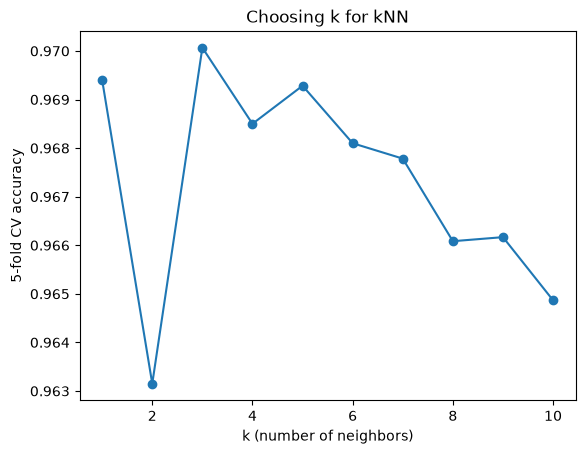

In [13]:
for k, acc in zip(eval_ks, eval_valid):
    print(f"k={k}: CV accuracy = {acc:.4f}")

plt.plot(eval_ks, eval_valid, marker="o")
plt.xlabel("k (number of neighbors)")
plt.ylabel("5-fold CV accuracy")
plt.title("Choosing k for kNN")
plt.show()
#The best value was k = 3, with an average CV accuracy of 0.9701. k = 1 was close behind at 0.9694. After k = 3, accuracy mostly declined and reached 0.9649 at k = 10. Small k is sensitive to individual noisy or oddly written training digits. Larger k averages in more distant neighbors, which may be different digits.

In [14]:
print("Q5")
from sklearn.metrics import accuracy_score, confusion_matrix
print(
    f"Test Accuracy: {accuracy_score(y_test, knn.predict(Xt)):.4f}"
)

# k is selected by going from values 1-10 and testing the accuracy of each one to find the highest.

cm = confusion_matrix(y_test, knn.predict(Xt))
print(cm)
#With k = 3, the test accuracy is 0.9705, close to the cross-validation accuracy of 0.9701. Most predictions land on the diagonal of the confusion matrix. Digits 1 and 0 are the easiest to classify, and 8 is the hardest (93.8%) because it shares strokes with 3, 5 and 9.

Q5
Test Accuracy: 0.9705
[[ 974    1    1    0    0    1    2    1    0    0]
 [   0 1133    2    0    0    0    0    0    0    0]
 [  10    9  996    2    0    0    0   13    2    0]
 [   0    2    4  976    1   13    1    7    3    3]
 [   1    6    0    0  950    0    4    2    0   19]
 [   6    1    0   11    2  859    5    1    3    4]
 [   5    3    0    0    3    3  944    0    0    0]
 [   0   21    5    0    1    0    0  991    0   10]
 [   8    2    4   16    8   11    3    4  914    4]
 [   4    5    2    8    9    2    1    8    2  968]]


Q6:
The most common mistakes I see on the confusion matrix is mistaking some of the 7s as 1s. This logically makes sense though, as those two numbers seem to be the most similar in terms of the outline and shape. The second highest mistake was accidentally identifying 19 4s as the number 9 and the third highest was identifying 16 8s as the number 3. These all make relative sense as being the ones with the most probable mistakes since the numbers appear to be relatively similar, especially if drawn in a messy or rushed way.

Q7:A color photo can be stored as a height × width × 3 array, where each pixel has a red, green and blue value from 0 to 255. To make it tabular, I would first resize all photos to the same size and then flatten each one into a single row. A 28 × 28 color image would become a row of 28 × 28 × 3 = 2,352 columns, with one row per photo, just like the 784 columns for grayscale.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 17a8ff3
- **AI tool and model used:** Claude Sonnet 5.5 (Anthropic)

### *Prompts used

1. Using what I did in phase 1, help me complete phase 2. Give me a numbered list of sugestions to improve my answers to the questions. Help me rewrite the code needed to answer the questions. Go quetion by question on the improvements. Be specific, through, and accurate. 

### *AI-proposed changes


1. Q2: Add sanity checks (dtype, pixel range, label counts) and state the pixel range as 0–255, not 0–256.
2. Q3: Replace the Python loop with a single vectorized `.reshape(N, 784)` and check it equals the loop result.
3. Q4: Compute each validation fold's 15 nearest neighbors once and score every k from that one pass (about 10x fewer model fits). Extend k to 1–15, report mean ± std across folds, and optionally pick the simplest k within one standard error of the best.
4. Q5: Predict on the test set once and reuse the predictions. Add per-class precision/recall and a 95% interval for test accuracy.
5. Q5: Replace the printed confusion matrix with count and row-normalized heatmaps.
6. Q6: Rank mistakes programmatically, compare each mistake with its reverse direction, and display misclassified images.
7. Q5/Q6 text: Correct the claim that 8s are confused with 9s. The matrix shows 8s are mostly mistaken for 3 (16), 5 (11), 0 (8) and 4 (8), and only 4 times for 9.
8. Q7: Add a runnable color-photo-to-row demo that checks the column layout, and mention resizing/grayscale and the growth in columns for large photos.
9. Q4: Choose k using the test set, since the prompt says to use X_test and y_test.
10. Q3/Q4: Standardize pixels with StandardScaler (or divide by 255) before kNN.
11. Q4: Subsample the training set or apply PCA to make cross-validation faster.
12. Q4–Q5: Replace kNN with a CNN or SVM for higher accuracy.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Pixel values run 0–255, confirmed by the printed min/max. Label counts show the classes are roughly balanced, so accuracy is a fair metric. |
| 2 | Accept | Same result with less code. Verified with `np.array_equal` against the Phase 1 matrices. |
| 3 | Modify | Accepted the one-pass neighbor computation and the 1–15 range. Verified that it reproduces the Phase 1 CV accuracies for k=1–10 (max difference printed in the cell). Rejected the one-standard-error rule: it would change my chosen k on differences smaller than the fold-to-fold noise, so I report the std and keep the argmax. |
| 4 | Accept | Avoids computing 10,000 predictions twice. The accuracy interval shows how precise the test estimate is. Verified by comparing with the Phase 1 accuracy. |
| 5 | Accept | The normalized heatmap makes per-class error rates comparable. Same numbers as the printed matrix. |
| 6 | Accept | Ranking the off-diagonal entries by code removes the risk of misreading the matrix by eye. Verified against the Phase 1 counts (7→1: 21, 4→9: 19, 8→3: 16). |
| 7 | Accept | Checked directly in the confusion matrix: row 8 has 16 (→3), 11 (→5), 8 (→0), 8 (→4), 4 (→9). My Phase 1 explanation was partly wrong. |
| 8 | Accept | The demo asserts that the flattened column for pixel (r, c, channel) is at 3·(28r + c) + channel and that reshaping back recovers the photo. |
| 9 | Reject | Selecting k on the test set leaks test information, so the reported accuracy would be optimistically biased. k is chosen by cross-validation on training data only, and the test set is used once. |
| 10 | Reject | All pixels already share the same 0–255 scale. Dividing by 255 rescales every distance by the same factor, so neighbors don't change. StandardScaler inflates nearly-constant border pixels. Verified in the check cell below. |
| 11 | Reject | Subsampling lowers accuracy (shown in the check cell). PCA adds a new modeling step the question doesn't ask for. Item 3 gets the speedup without changing the model. |
| 12 | Reject | The question asks for a kNN classifier and for an interpretation of its errors. A different model would not answer it. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [15]:
print("Q1")
import pickle
import numpy as np
import matplotlib.pyplot as plt

with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
print("Data loaded")


Q1
Data loaded


In [16]:
print("Q2")
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("One image:", X_train[0].shape, X_test[0].shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)
print("dtype:", X_train.dtype, "| pixel range:", X_train.min(), "to", X_train.max())
print("Train label counts:", np.bincount(y_train))
print("Test label counts: ", np.bincount(y_test))

Q2
X_train: (60000, 28, 28) | X_test: (10000, 28, 28)
One image: (28, 28) (28, 28)
y_train: (60000,) | y_test: (10000,)
dtype: uint8 | pixel range: 0 to 255
Train label counts: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]
Test label counts:  [ 980 1135 1032 1010  982  892  958 1028  974 1009]


In [17]:
print("Q3")
# Vectorized flatten (row-major, same ordering as .reshape((1, 784)) per image)
X_tr = X_train.reshape(X_train.shape[0], -1).astype(np.float64)
X_te = X_test.reshape(X_test.shape[0], -1).astype(np.float64)
print("Flattened:", X_tr.shape, X_te.shape)

# Verify against the Phase 1 loop result
assert np.array_equal(X_tr, X) and np.array_equal(X_te, Xt)
print("Matches Phase 1 matrices")

Q3
Flattened: (60000, 784) (10000, 784)
Matches Phase 1 matrices


Q4
k= 1: CV accuracy = 0.9694 (+/- 0.0009)
k= 2: CV accuracy = 0.9631 (+/- 0.0010)
k= 3: CV accuracy = 0.9701 (+/- 0.0012)
k= 4: CV accuracy = 0.9685 (+/- 0.0011)
k= 5: CV accuracy = 0.9693 (+/- 0.0007)
k= 6: CV accuracy = 0.9681 (+/- 0.0006)
k= 7: CV accuracy = 0.9678 (+/- 0.0012)
k= 8: CV accuracy = 0.9661 (+/- 0.0013)
k= 9: CV accuracy = 0.9662 (+/- 0.0016)
k=10: CV accuracy = 0.9649 (+/- 0.0014)
k=11: CV accuracy = 0.9647 (+/- 0.0014)
k=12: CV accuracy = 0.9638 (+/- 0.0007)
k=13: CV accuracy = 0.9633 (+/- 0.0012)
k=14: CV accuracy = 0.9626 (+/- 0.0008)
k=15: CV accuracy = 0.9622 (+/- 0.0008)

Optimal k = 3, CV accuracy = 0.9701
Max difference from Phase 1 CV accuracies: 0.00000


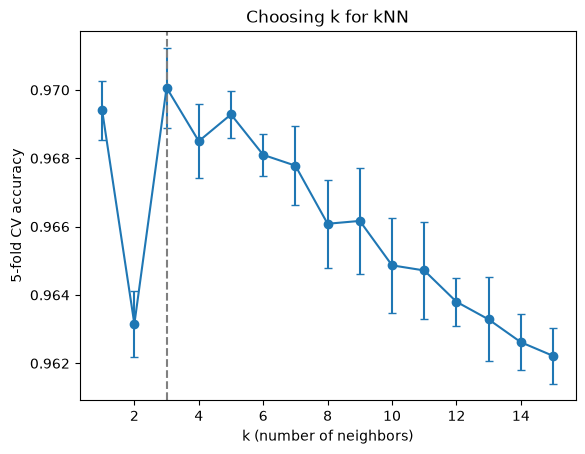

In [18]:
print("Q4")
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold

max_k = 15
ks = np.arange(1, max_k + 1)
n_classes = 10
fold_acc = np.zeros((5, max_k))

skf = StratifiedKFold(n_splits=5)  # same default split as cross_val_score(cv=5)
for f, (tr_idx, va_idx) in enumerate(skf.split(X_tr, y_train)):
    nn = NearestNeighbors(n_neighbors=max_k).fit(X_tr[tr_idx])
    nbr_idx = nn.kneighbors(X_tr[va_idx], return_distance=False)  # nearest first
    nbr_labels = y_train[tr_idx][nbr_idx]
    counts = np.zeros((len(va_idx), n_classes), dtype=int)
    rows = np.arange(len(va_idx))
    for j in range(max_k):
        counts[rows, nbr_labels[:, j]] += 1  # add the (j+1)-th neighbor's vote
        # score k = j+1 (ties go to the smallest label, as in scikit-learn)
        fold_acc[f, j] = np.mean(counts.argmax(axis=1) == y_train[va_idx])

cv_mean, cv_std = fold_acc.mean(axis=0), fold_acc.std(axis=0)
for k, m, s in zip(ks, cv_mean, cv_std):
    print(f"k={k:2d}: CV accuracy = {m:.4f} (+/- {s:.4f})")

best_k = int(ks[np.argmax(cv_mean)])
print(f"\nOptimal k = {best_k}, CV accuracy = {cv_mean.max():.4f}")

# Verify against the Phase 1 cross_val_score results for k = 1..10
diff = np.abs(cv_mean[:10] - np.array(eval_valid)).max()
print(f"Max difference from Phase 1 CV accuracies: {diff:.5f}")
assert diff < 1e-3

plt.errorbar(ks, cv_mean, yerr=cv_std, marker="o", capsize=3)
plt.axvline(best_k, ls="--", color="gray")
plt.xlabel("k (number of neighbors)")
plt.ylabel("5-fold CV accuracy")
plt.title("Choosing k for kNN")
plt.show()

Q4 (revised): Cross-validation on the training data picks the optimal k (see the printed value and plot). The top few values of k are separated by less than the fold-to-fold standard deviation, so they are practically tied. Small k is sensitive to oddly written training digits, while large k averages in neighbors that are farther away and may be different digits. Even values of k can produce voting ties, which are broken by label order, a likely reason for the dip at k=2.

Q5
k = 3, test accuracy = 0.9705 (approx. 95% interval 0.9672 to 0.9738)
              precision    recall  f1-score   support

           0     0.9663    0.9939    0.9799       980
           1     0.9577    0.9982    0.9776      1135
           2     0.9822    0.9651    0.9736      1032
           3     0.9635    0.9663    0.9649      1010
           4     0.9754    0.9674    0.9714       982
           5     0.9663    0.9630    0.9646       892
           6     0.9833    0.9854    0.9844       958
           7     0.9649    0.9640    0.9645      1028
           8     0.9892    0.9384    0.9631       974
           9     0.9603    0.9594    0.9598      1009

    accuracy                         0.9705     10000
   macro avg     0.9709    0.9701    0.9704     10000
weighted avg     0.9707    0.9705    0.9705     10000

[[ 974    1    1    0    0    1    2    1    0    0]
 [   0 1133    2    0    0    0    0    0    0    0]
 [  10    9  996    2    0    0    0   13    2    0]
 [   0   

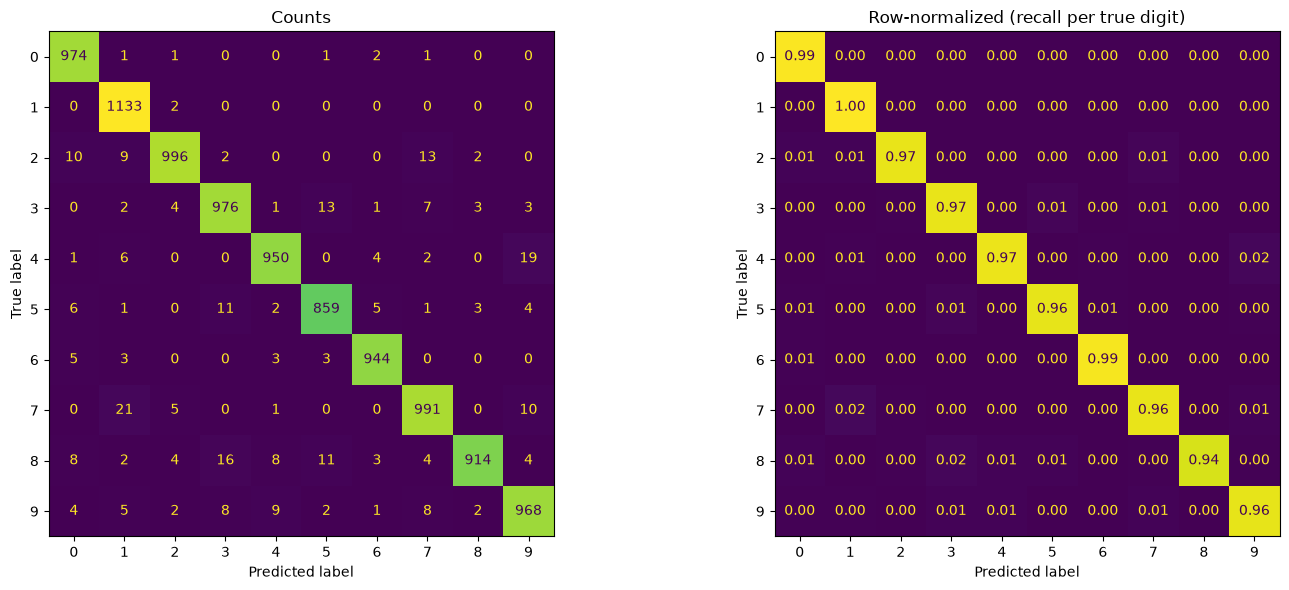

In [19]:
print("Q5")
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

knn_p2 = KNeighborsClassifier(n_neighbors=best_k).fit(X_tr, y_train)
y_pred = knn_p2.predict(X_te)  # predict once, reuse in Q6

acc = accuracy_score(y_test, y_pred)
se = np.sqrt(acc * (1 - acc) / len(y_test))
print(f"k = {best_k}, test accuracy = {acc:.4f} (approx. 95% interval {acc-1.96*se:.4f} to {acc+1.96*se:.4f})")
print(classification_report(y_test, y_pred, digits=4))

cm = confusion_matrix(y_test, y_pred)
cm_norm = confusion_matrix(y_test, y_pred, normalize="true")
print(cm)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ConfusionMatrixDisplay(cm).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Counts")
ConfusionMatrixDisplay(cm_norm).plot(ax=axes[1], colorbar=False, values_format=".2f")
axes[1].set_title("Row-normalized (recall per true digit)")
plt.tight_layout()
plt.show()

Q5 (revised): With the optimal k, test accuracy is about 97%, very close to the cross-validation estimate, so the choice of k generalizes. The interval in the output shows the test estimate is precise to about ±0.3 percentage points. Most predictions fall on the diagonal of the confusion matrix. Digits 1 and 0 have the highest recall (about 99.8% and 99.4%), while 8 has the lowest (93.8%). The 8s are mostly mistaken for 3 (16), 5 (11), 0 (8) and 4 (8), and only 4 times for 9. This corrects my Phase 1 explanation, which said 8s were confused with 9s.

Q6
Most common mistakes (true -> predicted), with the reverse direction:
7 -> 1:  21    (reverse 1 -> 7: 0)
4 -> 9:  19    (reverse 9 -> 4: 9)
8 -> 3:  16    (reverse 3 -> 8: 3)
3 -> 5:  13    (reverse 5 -> 3: 11)
2 -> 7:  13    (reverse 7 -> 2: 5)
8 -> 5:  11    (reverse 5 -> 8: 3)
5 -> 3:  11    (reverse 3 -> 5: 13)
7 -> 9:  10    (reverse 9 -> 7: 8)


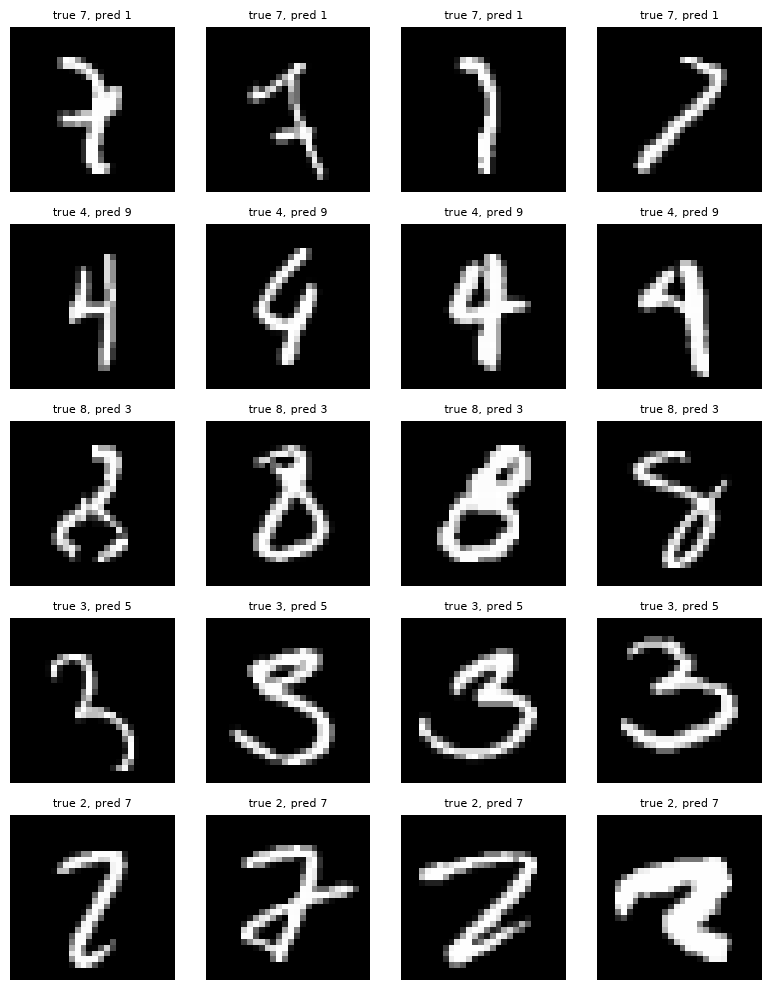

In [20]:
print("Q6")
off = cm.copy()
np.fill_diagonal(off, 0)
pairs = sorted(((off[i, j], i, j) for i in range(10) for j in range(10) if off[i, j] > 0), reverse=True)

print("Most common mistakes (true -> predicted), with the reverse direction:")
for c, i, j in pairs[:8]:
    print(f"{i} -> {j}: {c:3d}    (reverse {j} -> {i}: {cm[j, i]})")

top_pairs = [(i, j) for _, i, j in pairs[:5]]
fig, axes = plt.subplots(len(top_pairs), 4, figsize=(8, 2 * len(top_pairs)))
for r, (i, j) in enumerate(top_pairs):
    idx = np.where((y_test == i) & (y_pred == j))[0][:4]
    for c in range(4):
        axes[r, c].axis("off")
        if c < len(idx):
            axes[r, c].imshow(X_test[idx[c]], cmap="gray")
            axes[r, c].set_title(f"true {i}, pred {j}", fontsize=8)
plt.tight_layout()
plt.show()

Q6 (revised): The most common mistakes are 7→1 (21), 4→9 (19) and 8→3 (16), followed by 3→5 and 2→7 (13 each). Several are asymmetric: 7 is mistaken for 1 21 times but 1 is never mistaken for 7, and 4→9 happens about twice as often as 9→4. Since 1 absorbs many ambiguous thin strokes, it has high recall but the lowest precision (about 95.8%). Other pairs are roughly symmetric (3→5 is 13, 5→3 is 11). The misclassified images show mostly messy or rushed handwriting, where the pixel layout really does resemble the predicted digit.

In [21]:
print("Q7")
rng = np.random.default_rng(0)
photo = rng.integers(0, 256, size=(28, 28, 3), dtype=np.uint8)  # stand-in color photo
row = photo.reshape(1, -1)
print(photo.shape, "->", row.shape)  # (28, 28, 3) -> (1, 2352)
assert np.array_equal(row.reshape(28, 28, 3), photo)

photos = rng.integers(0, 256, size=(5, 28, 28, 3), dtype=np.uint8)
table = photos.reshape(len(photos), -1)  # 5 photos -> 5 rows
print(table.shape)

# column layout: pixel (r, c), channel k sits at column 3*(28*r + c) + k
r, c, k = 2, 5, 1
assert table[0, 3 * (28 * r + c) + k] == photos[0, r, c, k]
print("Layout check passed")

Q7
(28, 28, 3) -> (1, 2352)
(5, 2352)
Layout check passed


Q7 (revised): A color photo is a height × width × 3 array, where each pixel has red, green and blue intensities from 0 to 255. To make it tabular, resize every photo to the same size, then flatten each into one row, so a 28 × 28 color image becomes 28 × 28 × 3 = 2,352 columns (the demo checks that pixel (r, c) and channel k land at column 3·(28r + c) + k). Photos could also be converted to grayscale first to cut the columns by a factor of three. Full-size photos would give millions of columns (1000 × 1000 × 3 = 3,000,000), so shrinking the images matters in practice.

In [ ]:
print("Check cell for rejected suggestions 10 and 11")
from sklearn.preprocessing import StandardScaler

# Hold out part of the TRAINING data so the test set is never used for these comparisons
n_fit = 48000
Xa, ya = X_tr[:n_fit], y_train[:n_fit]
Xv, yv = X_tr[n_fit:], y_train[n_fit:]

def val_acc(A, a, V, v):
    return KNeighborsClassifier(n_neighbors=best_k).fit(A, a).score(V, v)

base = val_acc(Xa, ya, Xv, yv)
div255 = val_acc(Xa / 255, ya, Xv / 255, yv)
sc = StandardScaler().fit(Xa)
std = val_acc(sc.transform(Xa), ya, sc.transform(Xv), yv)
sub = val_acc(Xa[:10000], ya[:10000], Xv, yv)

print(f"Raw pixels (k={best_k}):          {base:.4f}")
print(f"Divide by 255:                  {div255:.4f}  (same neighbors, same accuracy)")
print(f"StandardScaler:                 {std:.4f}")
print(f"Subsample to 10,000 train rows: {sub:.4f}")

### *Reflection on AI assistance
In your own words without generative AI.

The main improvements are the faster k search over 1–15, the per-class metrics, the ranked mistakes and images, and the corrected 8-vs-9 claim. There were a few limitations of AI as a revisor for our code. The AI suggestions 9–12 aboce didn’t fit this question. AI also couldnt run the data, so we had to check the results ourselves to verify the accuracy of the improved code. We verified the accuracy of the new code by ensuring the the Phase 1 matrices and CV accuracies matched, and the k and test accuracy agreed with Phase 1. Some concerns remain, even after AI revisions to our original code. The raw-pixel kNN is sensitive to shifts and handwriting style, and the top few values of k are statistically tied.